# Assignment 1 — Data Profiling (EDA) Report

**Team member:** HAN NINGXI (A204195)

## 1. Scenario
An analyst is checking whether the UCI Adult census sample is usable for a study of income-category data quality across demographic groups. The dataset fits this task because it has explicit unknown markers, duplicate records, inconsistent target labels between files, extreme numerical values, and sensitive demographic fields. The diagnostic questions are: where are values missing, which values look unusual, and how do the recorded sex and race groups differ in size and missingness?

This is a **data-quality audit**, not an income prediction model or a claim about population income patterns.

## 2. Data source and how to run

**Source:** [UCI Machine Learning Repository: Adult](https://archive.ics.uci.edu/dataset/2/adult), originally extracted from the 1994 US Census database. This notebook downloads the [official UCI ZIP archive](https://archive.ics.uci.edu/static/public/2/adult.zip) directly using Python's standard library, then reads `adult.data` and `adult.test`. No scraping or authentication is used. The UCI repository page and `adult.names` describe the columns and collection context.

**Run:** Open this `.ipynb` in JupyterLab, Jupyter Notebook, or Google Colab with Python 3.10 or later. Install packages with `python -m pip install pandas numpy matplotlib seaborn`, then select **Run All**. Internet access is needed to download the official ZIP file. The code uses only in-memory data and does not require local paths or credentials.

The original train/test file labels are retained as `source_split` for tracing. They are combined only for this audit; a later modeling task should respect the original split and prevent duplicate leakage.

In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()
with ZipFile(BytesIO(archive_bytes)) as archive:
    train = pd.read_csv(archive.open("adult.data"), names=COLUMNS, skipinitialspace=True)
    test = pd.read_csv(archive.open("adult.test"), names=COLUMNS, skiprows=1, skipinitialspace=True)

train["source_split"] = "train"
test["source_split"] = "test"
raw = pd.concat([train, test], ignore_index=True)
print(f"Rows: {len(raw):,}; columns: {len(COLUMNS)} data fields + source_split")
display(raw.head(3))

Rows: 48,842; columns: 15 data fields + source_split


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source_split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train


## 3. Profiling and issue handling

### 3.1 Initial structure and missing values
The source represents unknown categories as the literal `?`, so a default null count alone would miss them. The next cell measures the markers before converting them to proper missing values. Missingness percentages use all 48,842 source rows as the denominator.

In [2]:
missing_markers = raw[COLUMNS].eq("?").sum().sort_values(ascending=False)
missing_report = pd.DataFrame({
    "missing_count": missing_markers,
    "percent_of_rows": (100 * missing_markers / len(raw)).round(2),
})
display(missing_report.query("missing_count > 0"))
print("Ordinary nulls in source:", int(raw[COLUMNS].isna().sum().sum()))

profile = raw.copy()
category_cols = profile.select_dtypes(include=["object", "str"]).columns
for col in category_cols:
    profile[col] = profile[col].astype("string").str.strip()
profile[COLUMNS] = profile[COLUMNS].replace("?", pd.NA)
print("Nulls after converting '?' markers:")
display(profile[COLUMNS].isna().sum().loc[lambda s: s > 0].sort_values(ascending=False))

,missing_count,percent_of_rows
occupation,2809,5.75
workclass,2799,5.73
native_country,857,1.75


Ordinary nulls in source: 0
Nulls after converting '?' markers:


occupation        2809
workclass         2799
native_country     857
dtype: int64

**Decision:** Keep rows with unknown `workclass`, `occupation`, or `native_country`. Dropping every row with an unknown value would discard thousands of records and could alter group composition. Create a missingness flag for each affected field and fill its category with `Unknown`, preserving the fact that it was missing rather than pretending to know its value. The flags support later checks for non-random missingness.

In [3]:
missing_fields = ["workclass", "occupation", "native_country"]
for col in missing_fields:
    profile[f"{col}_was_missing"] = profile[col].isna()
    profile[col] = profile[col].fillna("Unknown")
print("Remaining nulls in original fields:", int(profile[COLUMNS].isna().sum().sum()))

Remaining nulls in original fields: 0


### 3.2 Other quality issues
The test file appends a period to income labels, making four text values for a two-category target. Strip that terminal period. Count exact duplicate rows across the 15 data fields (excluding `source_split`) both before and after standardization; fixing the labels reveals additional matches. Without a stable person identifier, identical records could also represent different people, so duplicate removal is a conservative choice for this diagnostic sample and should be revisited for population estimation. We also coerce the six numerical fields to numeric and check basic validity rules and the education text/code mapping.

In [4]:
print("Income labels before fix:")
display(raw["income"].value_counts(dropna=False))
print("Exact duplicates before standardization:", int(raw.duplicated(subset=COLUMNS).sum()))
profile["income"] = profile["income"].str.removesuffix(".")
print("Income labels after fix:")
display(profile["income"].value_counts(dropna=False))

numeric_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
for col in numeric_cols:
    profile[col] = pd.to_numeric(profile[col], errors="coerce")

checks = pd.Series({
    "age outside 17–90": (~profile["age"].between(17, 90)).sum(),
    "hours_per_week outside 1–99": (~profile["hours_per_week"].between(1, 99)).sum(),
    "fnlwgt <= 0": (profile["fnlwgt"] <= 0).sum(),
    "negative capital_gain/loss": ((profile["capital_gain"] < 0) | (profile["capital_loss"] < 0)).sum(),
    "invalid income label": (~profile["income"].isin(["<=50K", ">50K"])).sum(),
    "numeric conversion nulls": profile[numeric_cols].isna().sum().sum(),
})
display(checks.to_frame("rows"))

education_code_counts = profile.groupby("education", dropna=False)["education_num"].nunique()
print("Education labels mapped to more than one numeric code:", int((education_code_counts > 1).sum()))
duplicate_mask = profile.duplicated(subset=COLUMNS, keep="first")
print("Exact duplicate records across 15 fields:", int(duplicate_mask.sum()))
clean = profile.loc[~duplicate_mask].copy().reset_index(drop=True)
print("Rows after deduplication:", f"{len(clean):,}")

Income labels before fix:


income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

Exact duplicates before standardization: 29
Income labels after fix:


income
<=50K    37155
>50K     11687
Name: count, dtype: Int64

,rows
age outside 17–90,0
hours_per_week outside 1–99,0
fnlwgt <= 0,0
negative capital_gain/loss,0
invalid income label,0
numeric conversion nulls,0


Education labels mapped to more than one numeric code: 0
Exact duplicate records across 15 fields: 52
Rows after deduplication: 48,790


### 3.3 Outliers
Use Tukey's 1.5 × IQR rule on `hours_per_week` as a screen for unusual weekly hours. Because many people report 40 hours, the IQR is narrow and flags more than a quarter of records; the rule marks unusual values, not data-entry errors. For `capital_gain`, most values are zero, so Q1 = Q3 = 0 and the usual IQR rule would label every positive gain an outlier. Inspect its distribution separately. Retain values within the source's valid ranges and add a flag for unusual hours; do not cap or remove plausible observations without external validation.

In [5]:
q1, q3 = clean["hours_per_week"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
clean["hours_iqr_outlier"] = ~clean["hours_per_week"].between(lower, upper)
print(f"Hours IQR bounds: {lower:g} to {upper:g}; flagged: {clean['hours_iqr_outlier'].sum():,} ({clean['hours_iqr_outlier'].mean():.2%})")
print("Flagged hours range:", clean.loc[clean["hours_iqr_outlier"], "hours_per_week"].agg(["min", "max"]).to_dict())
print("Capital gain quartiles:", clean["capital_gain"].quantile([0, .25, .5, .75, .99, 1]).to_dict())
print("Positive capital gain records:", int(clean["capital_gain"].gt(0).sum()))

Hours IQR bounds: 32.5 to 52.5; flagged: 13,486 (27.64%)


Flagged hours range: {'min': 1, 'max': 99}
Capital gain quartiles: {0.0: 0.0, 0.25: 0.0, 0.5: 0.0, 0.75: 0.0, 0.99: 15024.0, 1.0: 99999.0}
Positive capital gain records: 4035


## 4. Exploratory diagnostic charts
These charts show data problems directly. The missing-value plot uses the source `?` markers before cleaning; the boxplot shows potential outliers; the final chart checks whether source records and missingness are balanced by recorded sex.

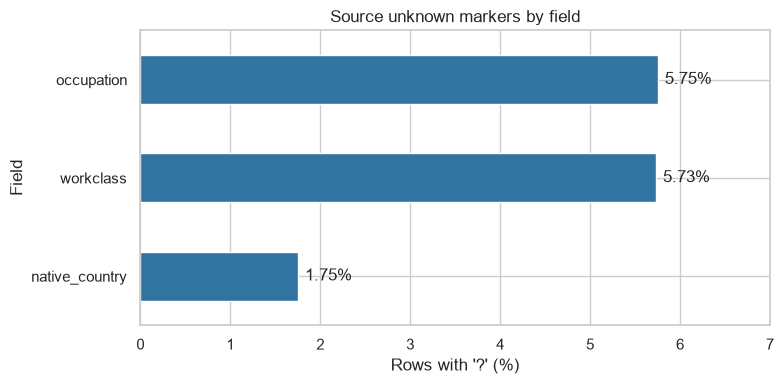

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
missing_report.query("missing_count > 0").sort_values("percent_of_rows")["percent_of_rows"].plot.barh(ax=ax, color="#3274a1")
ax.set(title="Source unknown markers by field", xlabel="Rows with '?' (%)", ylabel="Field")
for bar in ax.patches:
    ax.text(bar.get_width() + 0.08, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.2f}%", va="center")
ax.set_xlim(0, 7)
plt.tight_layout()
plt.show()

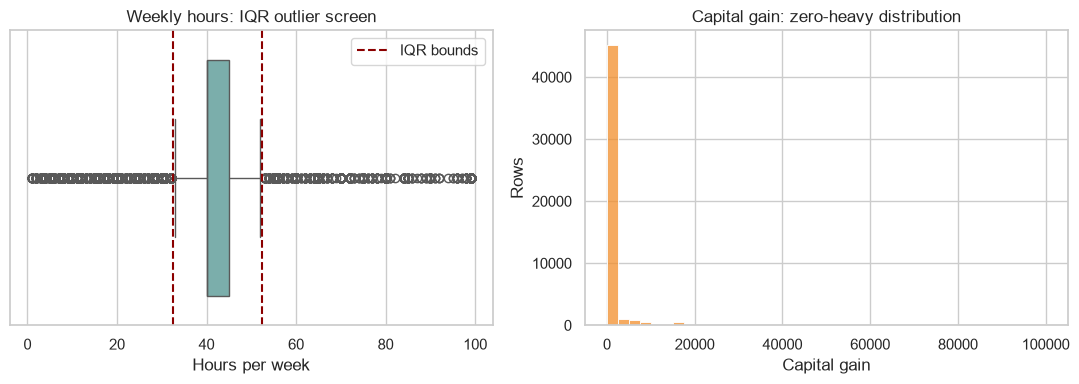

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=clean["hours_per_week"], ax=axes[0], color="#72b7b2")
axes[0].axvline(lower, color="darkred", linestyle="--", label="IQR bounds")
axes[0].axvline(upper, color="darkred", linestyle="--")
axes[0].set(title="Weekly hours: IQR outlier screen", xlabel="Hours per week")
axes[0].legend()
sns.histplot(clean["capital_gain"], bins=40, ax=axes[1], color="#f28e2b")
axes[1].set(title="Capital gain: zero-heavy distribution", xlabel="Capital gain", ylabel="Rows")
plt.tight_layout()
plt.show()

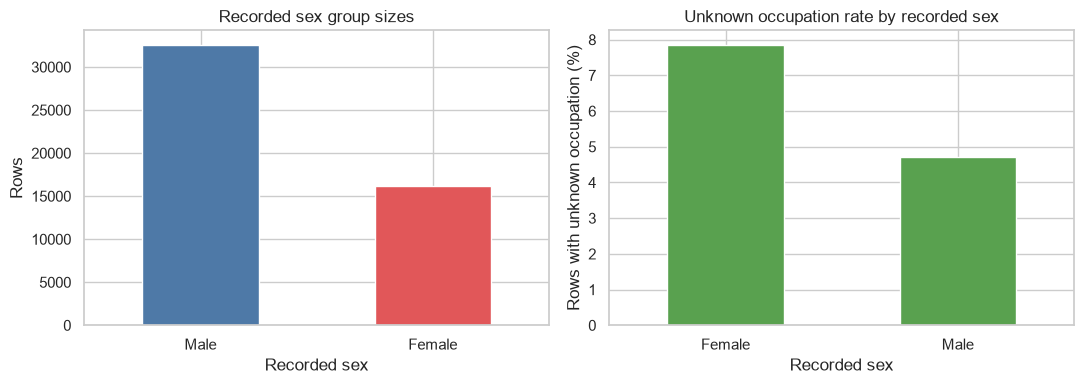

,rows
race,
White,41714
Black,4683
Asian-Pac-Islander,1517
Amer-Indian-Eskimo,470
Other,406


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
clean["sex"].value_counts().plot.bar(ax=axes[0], color=["#4e79a7", "#e15759"])
axes[0].set(title="Recorded sex group sizes", xlabel="Recorded sex", ylabel="Rows")
axes[0].tick_params(axis="x", rotation=0)
missing_by_sex = clean.groupby("sex")["occupation_was_missing"].mean().mul(100)
missing_by_sex.plot.bar(ax=axes[1], color="#59a14f")
axes[1].set(title="Unknown occupation rate by recorded sex", xlabel="Recorded sex", ylabel="Rows with unknown occupation (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(clean["race"].value_counts().rename("rows").to_frame())

## 5. PII and bias risks

The released data has no names, addresses, or direct personal identifiers, but combinations of age, sex, race, native country, occupation, and weekly hours are **quasi-identifiers**. Avoid publishing row-level extracts or small-group tables; limit access to raw records, aggregate results, and suppress tiny cells when sharing. `fnlwgt` is a census weight, not an individual ID.

The data was extracted from a 1994 US Census source using inclusion conditions described in `adult.names`, so it is historically and geographically narrow. The recorded `sex` field is binary and is not a complete representation of gender. Group sizes are unequal, and unknown categories may be distributed unevenly. Do not treat group differences here as causal or representative of current populations. For later modeling, check error and missingness rates by group, use the original split, and consider the documented sampling weight appropriately.

## 6. Conclusion

After converting `?` to missing values, preserving missingness flags, standardizing income labels, validating numeric ranges, and removing exact duplicate records, the data is fit for **diagnostic profiling of this historical sample**. The IQR hours flags and positive capital gains remain because the observed values can be legitimate and the source gives no evidence that they are errors. Remaining limits include unknown values, ambiguity about identical records, a zero-heavy gain distribution, unequal demographic groups, binary sex labels, and the age and geography of the source. Any inferential or predictive use needs additional validation and a documented treatment of weights and group fairness.